# mini-codex benchmark report

This notebook turns the benchmark results in `results/runs/*/results.csv` into the
tables and charts used in the report. It covers:

1. per-suite results: pass@1 with Wilson 95% intervals, iterations, time, tokens, cost
2. solve rate with confidence intervals
3. cost per solved task vs solve rate
4. the edit-test-retry loop vs a no-retry baseline
5. Jev router decisions and cascade escalations
6. the failure taxonomy
7. repeat-run reliability

**Reproducing it.** The committed results come from real runs through OpenRouter
(commands in the README). With no API keys, set `RUN_MOCK = True` below to add a fresh
offline run with the deterministic mock backend. Every chart is also written to
`results/figures/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "minicodex").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from minicodex.metrics import failure_taxonomy, reliability, router_stats, wilson_ci
from minicodex.report import FAILURES, load_runs, retry_pairs, suite_table

RUN_MOCK = False  # True: add an offline mock-backend run (no API key needed)
RUNS_DIR = ROOT / "results" / "runs"
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

if RUN_MOCK:
    from minicodex.bench import RunConfig, run_benchmark
    run_benchmark(RunConfig(suite="all", label="mock_all"), RUNS_DIR / "mock_all")

NAMES = {
    "sol_full": "Sol only",
    "luna_full": "Luna only",
    "jev_cascade_full": "Jev-routed + cascade",
    "sol_noretry": "Sol, no retry",
    "luna_noretry": "Luna, no retry",
    "mock_all": "Mock (offline)",
}
runs = load_runs(RUNS_DIR)
order = [k for k in NAMES if k in runs] + [k for k in runs if k not in NAMES]
runs = {k: runs[k] for k in order}
df = pd.concat([pd.DataFrame(rows) for rows in runs.values()], ignore_index=True)
for col in ["iterations", "wall_time_s", "total_tokens", "cost_usd", "router_latency_ms",
            "repeat", "steps"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["solved"] = df["solved"] == "True"
df["escalated"] = df["escalated"] == "True"
df["config"] = df["run"].map(lambda r: NAMES.get(r, r))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Sol only": "#4c72b0", "Luna only": "#dd8452", "Jev-routed + cascade": "#55a868",
          "Sol, no retry": "#8172b2", "Luna, no retry": "#c44e52",
          "Mock (offline)": "#999999"}
print(f"{len(runs)} runs, {len(df)} task attempts")
df.groupby("config", sort=False).agg(attempts=("task", "size"),
                                      repeats=("repeat", "max"),
                                      models=("models_used", lambda s: ", ".join(sorted(set(s)))))

6 runs, 608 task attempts


,attempts,repeats,models
config,,,
Sol only,114,3,openai/gpt-6.1-sol
Luna only,114,3,openai/gpt-5.6-luna
Jev-routed + cascade,114,3,"openai/gpt-5.6-luna, openai/gpt-6.1-sol"
"Sol, no retry",114,3,openai/gpt-6.1-sol
"Luna, no retry",114,3,openai/gpt-5.6-luna
Mock (offline),38,1,mock-strong


## 1. Results by configuration and suite

One row per configuration and suite. With `--repeat 3`, every task was attempted three
times, so `n` counts attempts. pass@1 is the share of attempts solved, graded against the
task's pristine tests. Cost is the billed cost OpenRouter reports, plus Jev's per-token
price for the routed configuration.

In [2]:
table = pd.DataFrame(suite_table(runs))
table["config"] = table["run"].map(lambda r: NAMES.get(r, r))
show = table.assign(
    **{"pass@1": (100 * table["pass_at_1"]).round(1),
       "95% CI": [f"{100*a:.1f}-{100*b:.1f}" for a, b in zip(table.ci_low, table.ci_high)],
       "mean iters": table["mean_iterations"].round(2),
       "mean time (s)": table["mean_wall_time_s"].round(1),
       "mean tokens": table["mean_tokens"].round(0).astype(int),
       "total cost ($)": table["total_cost_usd"].round(4),
       "cost/solved ($)": table["cost_per_solved_usd"].round(4)}
)[["config", "suite", "n", "solved", "pass@1", "95% CI", "mean iters", "mean time (s)",
   "mean tokens", "total cost ($)", "cost/solved ($)"]]
show.to_csv(FIG_DIR.parent / "summary_table.csv", index=False)
show

,config,suite,n,solved,pass@1,95% CI,mean iters,mean time (s),mean tokens,total cost ($),cost/solved ($)
0,Sol only,custom,24,24,100.0,86.2-100.0,1.12,9.9,4936,0.2396,0.0100
1,Sol only,humanevalfix,90,90,100.0,95.9-100.0,1.00,11.6,6737,1.1257,0.0125
2,Sol only,all,114,114,100.0,96.7-100.0,1.03,11.2,6358,1.3654,0.0120
3,Luna only,custom,24,24,100.0,86.2-100.0,1.12,9.8,5011,0.0290,0.0012
4,Luna only,humanevalfix,90,90,100.0,95.9-100.0,1.03,11.4,6984,0.1362,0.0015
5,Luna only,all,114,114,100.0,96.7-100.0,1.05,11.0,6569,0.1651,0.0014
6,Jev-routed + cascade,custom,24,24,100.0,86.2-100.0,1.04,9.4,4980,0.0745,0.0031
7,Jev-routed + cascade,humanevalfix,90,90,100.0,95.9-100.0,1.00,11.1,6597,0.1762,0.0020
8,Jev-routed + cascade,all,114,114,100.0,96.7-100.0,1.01,10.8,6257,0.2507,0.0022
9,"Sol, no retry",custom,24,21,87.5,69.0-95.7,1.00,10.0,4478,0.2278,0.0108


## 2. Solve rate with 95% confidence intervals

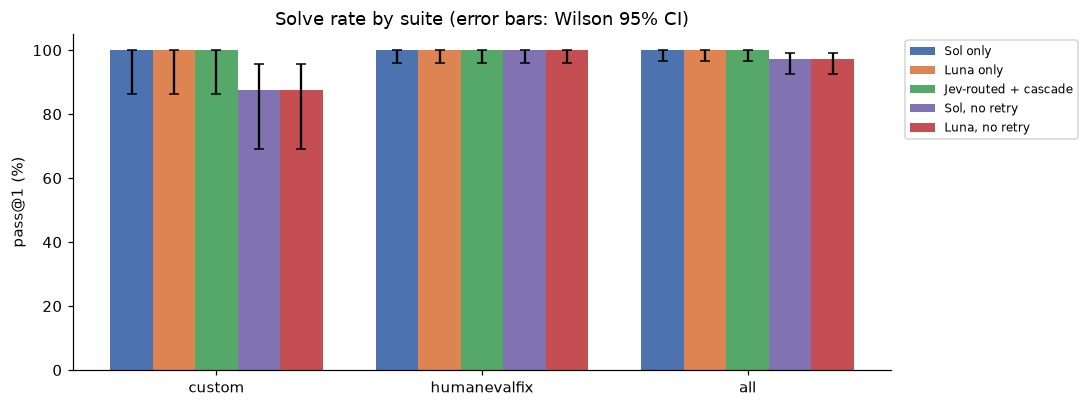

In [3]:
real = [NAMES.get(r, r) for r in runs if r != "mock_all"]
suites = ["custom", "humanevalfix", "all"]
fig, ax = plt.subplots(figsize=(10, 3.8))
width = 0.8 / max(1, len(real))
for i, cfg in enumerate(real):
    sub = table[table["config"] == cfg].set_index("suite").reindex(suites)
    x = [j + i * width for j in range(len(suites))]
    y = 100 * sub["pass_at_1"]
    err = [100 * (sub["pass_at_1"] - sub["ci_low"]), 100 * (sub["ci_high"] - sub["pass_at_1"])]
    ax.bar(x, y, width, yerr=err, capsize=3, label=cfg, color=COLORS.get(cfg))
ax.set_xticks([j + width * (len(real) - 1) / 2 for j in range(len(suites))], suites)
ax.set_ylabel("pass@1 (%)")
ax.set_ylim(0, 105)
ax.set_title("Solve rate by suite (error bars: Wilson 95% CI)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIG_DIR / "solve_rate_ci.png")
plt.show()

## 3. Cost per solved task vs solve rate

Each point is one configuration over all 38 tasks × repeats. Down and to the right is better:
cheaper per fix, more fixes.

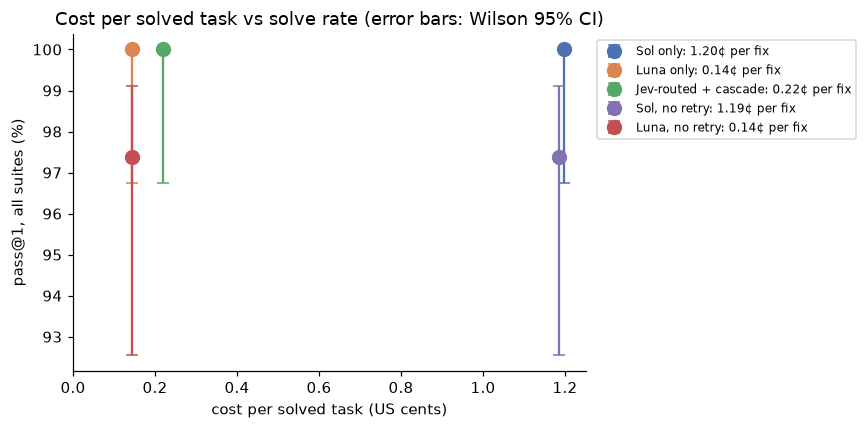

In [4]:
allrows = table[(table["suite"] == "all") & (table["config"].isin(real))]
fig, ax = plt.subplots(figsize=(8, 4))
for _, r in allrows.iterrows():
    err = [[100 * (r["pass_at_1"] - r["ci_low"])], [100 * (r["ci_high"] - r["pass_at_1"])]]
    ax.errorbar(100 * r["cost_per_solved_usd"], 100 * r["pass_at_1"], yerr=err, fmt="o", ms=9,
                capsize=4, color=COLORS.get(r["config"]),
                label=f"{r['config']}: {100 * r['cost_per_solved_usd']:.2f}¢ per fix")
ax.set_xlabel("cost per solved task (US cents)")
ax.set_ylabel("pass@1, all suites (%)")
ax.set_xlim(left=0)
ax.set_title("Cost per solved task vs solve rate (error bars: Wilson 95% CI)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIG_DIR / "cost_vs_solve_rate.png")
plt.show()

## 4. Retry loop vs no-retry baseline

The no-retry baseline (`--max-iterations 1`) lets the model make one patch, runs the tests,
and stops. The full loop allows up to 6 edit-and-test iterations. Each pair uses the same
model (Sol and Luna). "Rescued by retry" counts tasks that the full loop solved and the baseline did not.

,suite,no_retry,full,gain_pp,rescued_by_retry,no_retry_cost,full_cost
0,custom,87.5,100.0,12.5,1,0.227822,0.239649
1,humanevalfix,100.0,100.0,0.0,0,1.088809,1.125701
2,all,97.4,100.0,2.6,1,1.316631,1.365350
3,custom,87.5,100.0,12.5,1,0.027805,0.028958
4,humanevalfix,100.0,100.0,0.0,0,0.131127,0.136159
5,all,97.4,100.0,2.6,1,0.158932,0.165117


,model,suite,no_retry,full,gain_pp,rescued_by_retry,no_retry_cost,full_cost
0,Sol,custom,87.5,100.0,12.5,1,0.227822,0.239649
1,Sol,humanevalfix,100.0,100.0,0.0,0,1.088809,1.125701
2,Sol,all,97.4,100.0,2.6,1,1.316631,1.365350
3,Luna,custom,87.5,100.0,12.5,1,0.027805,0.028958
4,Luna,humanevalfix,100.0,100.0,0.0,0,0.131127,0.136159
5,Luna,all,97.4,100.0,2.6,1,0.158932,0.165117


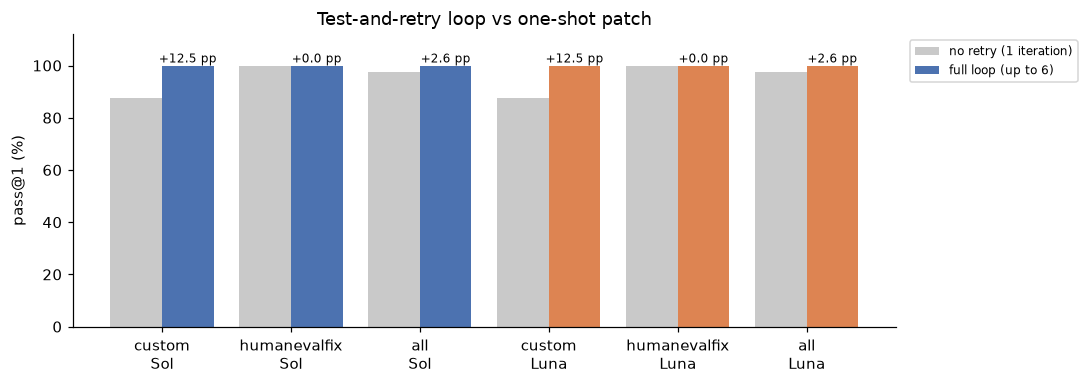

attempts  mean_iterations
config    task                                         
Luna only 04_two_file_bug            3              2.0
          hef_124_valid_date         2              2.0
          hef_129_minPath            1              2.0
Sol only  04_two_file_bug            3              2.0

In [5]:
pairs = pd.DataFrame(retry_pairs(runs))
if pairs.empty:
    print("no no-retry run found")
else:
    pairs_show = pairs.assign(
        no_retry=(100 * pairs.no_retry_pass).round(1), full=(100 * pairs.full_pass).round(1),
        gain_pp=pairs.gain_pp.round(1))[["suite", "no_retry", "full", "gain_pp",
                                          "rescued_by_retry", "no_retry_cost", "full_cost"]]
    display(pairs_show)
    pairs_show.insert(0, "model", pairs.full_run.map(lambda r: NAMES.get(r, r).split()[0]))
    fig, ax = plt.subplots(figsize=(10, 3.6))
    x = range(len(pairs))
    ax.bar([i - 0.2 for i in x], 100 * pairs.no_retry_pass, 0.4, label="no retry (1 iteration)",
           color="#c9c9c9")
    ax.bar([i + 0.2 for i in x], 100 * pairs.full_pass, 0.4, label="full loop (up to 6)",
           color=[COLORS.get(NAMES.get(r, r)) for r in pairs.full_run])
    for i, g in zip(x, pairs.gain_pp):
        ax.annotate(f"{g:+.1f} pp", (i + 0.2, 100 * pairs.full_pass.iloc[i]),
                    ha="center", va="bottom", fontsize=8)
    ax.set_xticks(list(x), [f"{s}\n{m}" for s, m in zip(pairs.suite, pairs_show.model)])
    ax.set_ylabel("pass@1 (%)")
    ax.set_ylim(0, 112)
    ax.set_title("Test-and-retry loop vs one-shot patch")
    display(pairs_show)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    fig.savefig(FIG_DIR / "retry_vs_noretry.png")
    plt.show()

# Which tasks needed more than one iteration in the full loop?
multi = df[df.run.isin(["sol_full", "luna_full"]) & (df.iterations > 1)]
multi.groupby(["config", "task"]).agg(attempts=("repeat", "size"), mean_iterations=("iterations", "mean"))

## 5. Router decisions (Jev + cascade)

For every task, Jev answers one Choice question, *cheap* (`openai/gpt-5.6-luna`) or *strong*
(`openai/gpt-6.1-sol`), and returns probabilities and a confidence. A cheap pick with
confidence below 0.6 goes to the strong model. With `--cascade`, a cheap-model failure after
2 iterations is retried from scratch on the strong model.

,router stats
tasks,114
tiers,"{'cheap': 107, 'strong': 7}"
sources,"{'jev': 113, 'low_confidence': 1}"
cheap_share,0.938596
escalated,0
cheap_solved_without_escalation,107
mean_confidence,0.922456
mean_latency_ms,140.214912
p95_latency_ms,185.1
router_cost_usd,0.003935


route_tier,cheap,strong,escalated
suite,,,
custom,20,4,0
humanevalfix,87,3,0


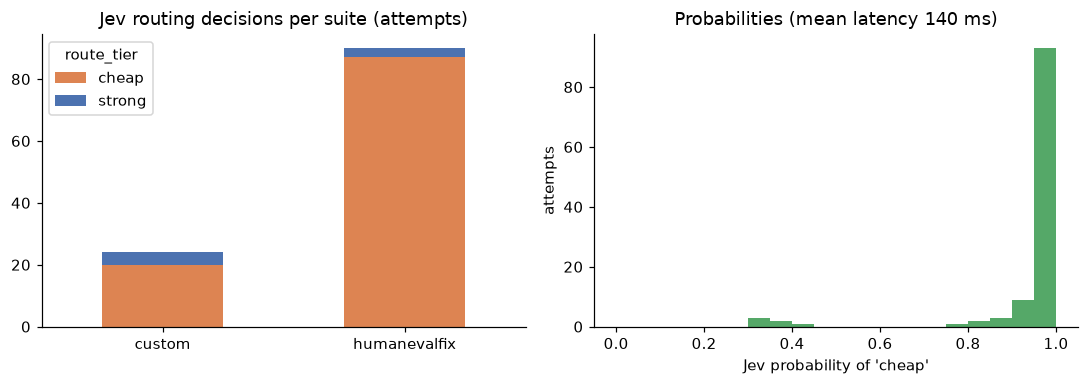

,suite,task,repeat,route_tier,router_confidence,router_p_cheap,router_latency_ms,escalated,models_used,solved
228,custom,01_off_by_one,1,cheap,1.0,1.0,164.7,False,openai/gpt-5.6-luna,True
229,custom,02_wrong_condition,1,cheap,1.0,1.0,161.8,False,openai/gpt-5.6-luna,True
230,custom,03_missing_edge_case,1,cheap,1.0,1.0,368.7,False,openai/gpt-5.6-luna,True
231,custom,04_two_file_bug,1,cheap,0.64,0.82,372.3,False,openai/gpt-5.6-luna,True
232,custom,05_feature_request,1,strong,0.24,0.38,136.8,False,openai/gpt-6.1-sol,True
233,custom,06_string_bug,1,cheap,1.0,1.0,192.9,False,openai/gpt-5.6-luna,True
234,custom,07_dict_bug,1,cheap,1.0,1.0,92.5,False,openai/gpt-5.6-luna,True
235,custom,08_search_bug,1,cheap,0.96,0.98,127.4,False,openai/gpt-5.6-luna,True
236,humanevalfix,hef_017_parse_music,1,cheap,1.0,1.0,129.5,False,openai/gpt-5.6-luna,True
237,humanevalfix,hef_022_filter_integers,1,cheap,1.0,1.0,110.8,False,openai/gpt-5.6-luna,True


In [6]:
routed = df[df.router == "jev"].copy()
if routed.empty:
    print("no routed run found")
else:
    rs = router_stats(routed.assign(solved=routed.solved.astype(str),
                                    escalated=routed.escalated.astype(str)).to_dict("records"))
    display(pd.Series(rs, name="router stats").to_frame())
    decisions = (routed.groupby(["suite", "route_tier"]).size().unstack(fill_value=0))
    decisions["escalated"] = routed.groupby("suite")["escalated"].sum()
    display(decisions)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
    decisions.drop(columns="escalated").plot.bar(stacked=True, ax=ax1,
                                                 color={"cheap": "#dd8452", "strong": "#4c72b0"})
    ax1.set_title("Jev routing decisions per suite (attempts)")
    ax1.set_xlabel(None)
    ax1.tick_params(axis="x", rotation=0)
    p = pd.to_numeric(routed.router_p_cheap, errors="coerce")
    ax2.hist(p, bins=20, range=(0, 1), color="#55a868")
    ax2.set_xlabel("Jev probability of 'cheap'")
    ax2.set_ylabel("attempts")
    ax2.set_title(f"Probabilities (mean latency {rs['mean_latency_ms']:.0f} ms)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "router_decisions.png")
    plt.show()
routed[["suite", "task", "repeat", "route_tier", "router_confidence", "router_p_cheap",
        "router_latency_ms", "escalated", "models_used", "solved"]].head(40)

## 5b. Bias check: solve rate by bug type and difficulty

A single headline number can hide a model that does well on one kind of bug and badly on
another. This breaks pass@1 down by HumanEvalFix bug type and by difficulty label for each
configuration. Cells with few attempts carry wide intervals, so they are shown with `n`.

In [7]:
real_df = df[df.run != "mock_all"]
def cell(g):
    lo, hi = wilson_ci(int(g.solved.sum()), len(g))
    return f"{100*g.solved.mean():.0f}% (n={len(g)}, CI {100*lo:.0f}-{100*hi:.0f})"
by_type = real_df[real_df.suite == "humanevalfix"].groupby(["category", "config"]).apply(
    cell, include_groups=False).unstack()
display(by_type)
by_diff = real_df.groupby(["difficulty", "config"]).apply(cell, include_groups=False).unstack()
by_diff

config,Jev-routed + cascade,Luna only,"Luna, no retry",Sol only,"Sol, no retry"
category,,,,,
excess logic,"100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)"
function misuse,"100% (n=3, CI 44-100)","100% (n=3, CI 44-100)","100% (n=3, CI 44-100)","100% (n=3, CI 44-100)","100% (n=3, CI 44-100)"
missing logic,"100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)"
operator misuse,"100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)"
value misuse,"100% (n=39, CI 91-100)","100% (n=39, CI 91-100)","100% (n=39, CI 91-100)","100% (n=39, CI 91-100)","100% (n=39, CI 91-100)"
variable misuse,"100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)","100% (n=12, CI 76-100)"


config,Jev-routed + cascade,Luna only,"Luna, no retry",Sol only,"Sol, no retry"
difficulty,,,,,
easy,"100% (n=54, CI 93-100)","100% (n=54, CI 93-100)","100% (n=54, CI 93-100)","100% (n=54, CI 93-100)","100% (n=54, CI 93-100)"
hard,"100% (n=18, CI 82-100)","100% (n=18, CI 82-100)","83% (n=18, CI 61-94)","100% (n=18, CI 82-100)","83% (n=18, CI 61-94)"
medium,"100% (n=42, CI 92-100)","100% (n=42, CI 92-100)","100% (n=42, CI 92-100)","100% (n=42, CI 92-100)","100% (n=42, CI 92-100)"


## 6. Failure taxonomy

Every unsolved attempt gets exactly one label: `wrong_fix` (the model finished, or stopped,
with tests still failing), `budget_exhausted` (iteration or step budget used up),
`invalid_action` (repeated malformed tool calls), `guardrail_block` (the model tried to
touch a protected file, such as the tests or a secret), or `api_error` (the provider failed
after retries).

,wrong_fix,budget_exhausted,invalid_action,guardrail_block,api_error
Sol only,0,0,0,0,0
Luna only,0,0,0,0,0
Jev-routed + cascade,0,0,0,0,0
"Sol, no retry",0,3,0,0,0
"Luna, no retry",0,3,0,0,0
Mock (offline),31,0,0,0,0


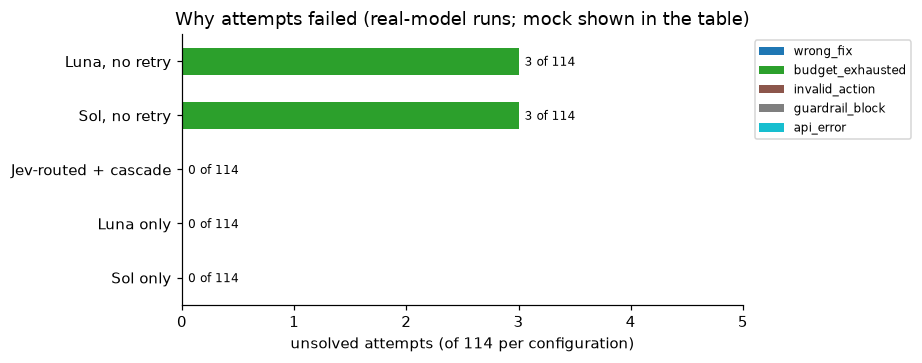

,config,suite,task,repeat,failure_reason,stop_reason,iterations,models_used,error
345,"Sol, no retry",custom,04_two_file_bug,1,budget_exhausted,budget_exhausted,1,openai/gpt-6.1-sol,
383,"Sol, no retry",custom,04_two_file_bug,2,budget_exhausted,budget_exhausted,1,openai/gpt-6.1-sol,
421,"Sol, no retry",custom,04_two_file_bug,3,budget_exhausted,budget_exhausted,1,openai/gpt-6.1-sol,
459,"Luna, no retry",custom,04_two_file_bug,1,budget_exhausted,budget_exhausted,1,openai/gpt-5.6-luna,
497,"Luna, no retry",custom,04_two_file_bug,2,budget_exhausted,budget_exhausted,1,openai/gpt-5.6-luna,
535,"Luna, no retry",custom,04_two_file_bug,3,budget_exhausted,budget_exhausted,1,openai/gpt-5.6-luna,
577,Mock (offline),custom,08_search_bug,1,wrong_fix,finished,0,mock-strong,
578,Mock (offline),humanevalfix,hef_017_parse_music,1,wrong_fix,finished,0,mock-strong,
579,Mock (offline),humanevalfix,hef_022_filter_integers,1,wrong_fix,finished,0,mock-strong,
580,Mock (offline),humanevalfix,hef_024_largest_divisor,1,wrong_fix,finished,0,mock-strong,


In [8]:
tax = pd.DataFrame({NAMES.get(k, k): failure_taxonomy(v) for k, v in runs.items()}).T
tax = tax.reindex(columns=list(FAILURES), fill_value=0).fillna(0).astype(int)
display(tax)
real_tax = tax.loc[[c for c in tax.index if c != "Mock (offline)"]]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
real_tax.plot.barh(stacked=True, ax=ax, colormap="tab10")
for i, total in enumerate(real_tax.sum(axis=1)):
    ax.annotate(f"{total} of 114", (total, i), xytext=(4, -3), textcoords="offset points",
                fontsize=8)
ax.set_xlabel("unsolved attempts (of 114 per configuration)")
ax.set_xlim(0, max(5, real_tax.values.sum(axis=1).max() + 2))
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Why attempts failed (real-model runs; mock shown in the table)")
fig.tight_layout()
fig.savefig(FIG_DIR / "failure_taxonomy.png")
plt.show()
df[~df.solved][["config", "suite", "task", "repeat", "failure_reason", "stop_reason",
                "iterations", "models_used", "error"]]

## 7. Reliability across repeats

Each configuration ran every task three times (`--repeat 3`). The table shows pass@1 per
repeat, its standard deviation, and the share of tasks with the same outcome on every repeat.

In [9]:
rel = pd.DataFrame({NAMES.get(k, k): reliability(v) for k, v in runs.items()}).T
rel["per_repeat_pass_at_1"] = rel["per_repeat_pass_at_1"].map(
    lambda xs: ", ".join(f"{100*x:.1f}%" for x in xs))
rel

,repeats,consistent_share,per_repeat_pass_at_1,stdev_pass_at_1
Sol only,3,1.0,"100.0%, 100.0%, 100.0%",0.0
Luna only,3,1.0,"100.0%, 100.0%, 100.0%",0.0
Jev-routed + cascade,3,1.0,"100.0%, 100.0%, 100.0%",0.0
"Sol, no retry",3,1.0,"97.4%, 97.4%, 97.4%",0.0
"Luna, no retry",3,1.0,"97.4%, 97.4%, 97.4%",0.0
Mock (offline),1,NaN,,NaN


## 8. Efficiency: steps, tokens and time per attempt

mean_steps  mean_tokens  mean_time_s  \
config               suite                                                
Sol only             custom             5.458     4935.500        9.921   
                     humanevalfix       5.778     6737.022       11.552   
Luna only            custom             5.583     5011.042        9.820   
                     humanevalfix       5.700     6984.467       11.360   
Jev-routed + cascade custom             5.583     4980.125        9.375   
                     humanevalfix       5.556     6597.389       11.121   
Sol, no retry        custom             5.292     4477.917       10.005   
                     humanevalfix       5.833     6823.422       11.875   
Luna, no retry       custom             5.333     4605.875        8.932   
                     humanevalfix       5.556     6603.022       10.879   

                                   total_cost  
config               suite                     
Sol only             custom             0.240  
                     humanevalfix       1.126  
Luna only            custom             0.029  
                     humanevalfix       0.136  
Jev-routed + cascade custom             0.074  
                     humanevalfix       0.176  
Sol, no retry        custom             0.228  
                     humanevalfix       1.089  
Luna, no retry       custom             0.028  
                     humanevalfix       0.131

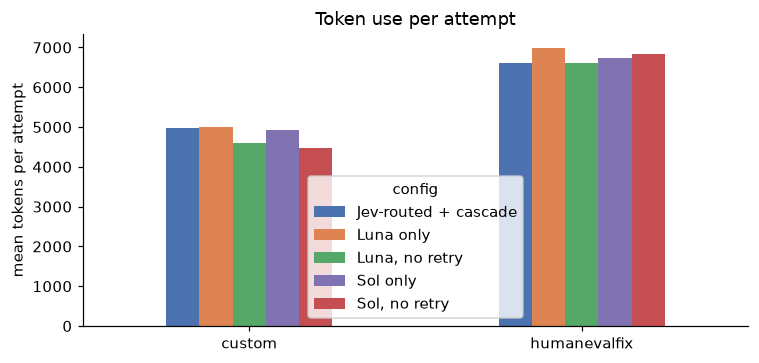

In [10]:
eff = df[df.run != "mock_all"].groupby(["config", "suite"], sort=False).agg(
    mean_steps=("steps", "mean"), mean_tokens=("total_tokens", "mean"),
    mean_time_s=("wall_time_s", "mean"), total_cost=("cost_usd", "sum")).round(3)
display(eff)
fig, ax = plt.subplots(figsize=(7, 3.4))
eff.reset_index().pivot(index="suite", columns="config", values="mean_tokens").plot.bar(
    ax=ax, color=[COLORS.get(c) for c in eff.reset_index().config.unique()])
ax.set_ylabel("mean tokens per attempt")
ax.set_xlabel(None)
ax.tick_params(axis="x", rotation=0)
ax.set_title("Token use per attempt")
fig.tight_layout()
fig.savefig(FIG_DIR / "tokens_per_attempt.png")
plt.show()

## 9. Reading the results (runs of 16 November 2026)

- **Quality hits the ceiling.** All three full-loop configurations (Sol only, Luna only,
  Jev-routed + cascade) solved 114/114 attempts: 100% pass@1, Wilson 95% CI 96.7-100%.
  On this benchmark the cheap model matches the strong one, so the comparison that matters
  is cost.
- **Cost per solved task** was 1.20¢ for Sol only, 0.14¢ for Luna only, and 0.22¢ for
  Jev-routed + cascade. Routing kept Sol's solve rate at about 18% of Sol's cost (82%
  cheaper). Jev sent 107 of 114 attempts to Luna and 7 to Sol: the feature request (3/3),
  `minPath` (3/3), and the two-file bug once, on low confidence. No cascade escalation
  was needed. Luna alone was cheaper still, because here routing paid for a few
  Sol calls that turned out to be unnecessary. Jev's own cost was about $0.004 for
  114 decisions (mean latency about 140 ms).
- **The retry loop matters on multi-step bugs.** With one patch and no retry, both Sol and
  Luna failed the two-file bug on every repeat (custom 87.5% vs 100%; +12.5 pp on custom,
  +2.6 pp overall). Retrying added only about 4% to the cost. On single-function
  HumanEvalFix bugs, both models usually fixed the bug in one edit.
- **Failures and reliability.** The only failures were `budget_exhausted` in the no-retry
  runs. There were no invalid actions, guardrail blocks, API errors or API retries. Every
  task had the same outcome in all three repeats. Jev's probabilities varied slightly
  between calls on borderline tasks, for example the two-file bug went to Luna twice and
  to Sol once.
- **Caveat.** HumanEval is public and the tasks are small, so these scores are optimistic
  for real enterprise code (see Limitations in the README). The near-100% ceiling means
  this benchmark can't show a quality gap between models. What it can show is the
  pipeline working end to end and the cost gap between configurations.